# Benchmark quantum memory: default and directional syndrome extraction

## Setup

In [1]:
%%capture
%pip install qldpc matplotlib sinter

In [2]:
import os
from collections.abc import Sequence

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import sinter
from matplotlib.figure import Figure

import directional_tile_codes as dtc
from qldpc import circuits, codes, decoders
from qldpc.objects import PauliXZLike

NUM_WORKERS = max(1, min(4, (os.cpu_count() or 1) - 1))

## Build Sinter tasks

In [8]:
def code_label(code: codes.CSSCode) -> str:
    """Return a compact quantum-code parameter label for a plot legend."""
    known_distance = code.get_distance_if_known()
    suffix = f", {known_distance}" if known_distance is not None else ""
    return f"[[{len(code)}, {code.dimension}{suffix}]]"


def run_memory_experiments(
    codes_and_rounds: Sequence[tuple[dtc.DirectionalTileCode, int]],
    basis: PauliXZLike,
    decoder: sinter.Decoder,
    *,
    error_rates: Sequence[float] = tuple(np.logspace(-3, -2, 5)),
    max_shots: int = 20_000,
    max_errors: int = 100,
) -> list[sinter.TaskStats]:
    """Compare both extraction strategies at equal actual syndrome-round counts."""
    for _, num_rounds in codes_and_rounds:
        if (
            isinstance(num_rounds, (bool, np.bool_))
            or not isinstance(num_rounds, (int, np.integer))
            or num_rounds < 2
            or num_rounds % 2
        ):
            raise ValueError("Each round count must be a positive even integer.")

    tasks = []
    for tile_code, num_rounds in codes_and_rounds:
        num_rounds = int(num_rounds)
        code = tile_code.css_code
        strategy = dtc.DirectionalSyndromeMeasurement(tile_code)
        word = "".join(direction.name for direction in tile_code.word.word)

        for extraction in ("default", "directional"):
            if extraction == "default":
                num_calls = num_rounds
                extraction_kwargs = {}
            else:
                num_calls = num_rounds // 2
                extraction_kwargs = {
                    "qubit_ids": strategy.get_qubit_ids(),
                    "syndrome_measurement_strategy": strategy,
                }

            for probability in error_rates:
                noise = circuits.DepolarizingNoiseModel(
                    float(probability),
                    include_idling_error=False,
                )
                circuit = circuits.get_memory_experiment(
                    code,
                    basis=basis,
                    num_rounds=num_calls,
                    noise_model=noise,
                    **extraction_kwargs,
                )
                # Validate annotations without dropping or decomposing faults.
                dem = circuit.detector_error_model()
                tasks.append(
                    sinter.Task(
                        circuit=circuit,
                        detector_error_model=dem,
                        json_metadata={
                            "label": code_label(code),
                            "word": word,
                            "basis": str(basis),
                            "strategy": extraction,
                            "probability": float(probability),
                            "num_rounds": num_rounds,
                            "extraction_calls": num_calls,
                        },
                    )
                )

    return sinter.collect(
        tasks=tasks,
        decoders=["qldpc"],
        custom_decoders={"qldpc": decoder},
        num_workers=NUM_WORKERS,
        max_shots=max_shots,
        max_errors=max_errors,
        print_progress=False,
    )


def plot_fixed_basis_results(
    codes_and_rounds: Sequence[tuple[dtc.DirectionalTileCode, int]],
    decoder: sinter.Decoder,
    *,
    error_rates: Sequence[float] = tuple(np.logspace(-3, -2, 5)),
    max_shots: int = 20_000,
    max_errors: int = 100,
) -> tuple[Figure, npt.NDArray[np.object_]]:
    """Plot default and directional extraction together in each X/Z panel."""
    figure, axes = plt.subplots(1, 2, sharey=True, figsize=(14, 5))
    markers = ("o", "s", "^", "D")

    for axis, basis in zip(axes, ("X", "Z")):
        stats = run_memory_experiments(
            codes_and_rounds,
            basis,
            decoder,
            error_rates=error_rates,
            max_shots=max_shots,
            max_errors=max_errors,
        )
        sinter.plot_error_rate(
            ax=axis,
            stats=stats,
            x_func=lambda stat: stat.json_metadata["probability"],
            group_func=lambda stat: (
                f"{stat.json_metadata['label']} {stat.json_metadata['word']}, "
                f"R={stat.json_metadata['num_rounds']} | "
                f"{stat.json_metadata['strategy']}"
            ),
            plot_args_func=lambda index, curve_id: {
                "marker": markers[index % len(markers)],
                "linestyle": "--" if curve_id.endswith(" | directional") else "-",
            },
        )
        reference_rates = sorted({stat.json_metadata["probability"] for stat in stats})
        axis.plot(
            reference_rates,
            reference_rates,
            color="black",
            linestyle=":",
            label=r"$p_{\mathrm{logical}}=p_{\mathrm{physical}}$",
        )
        axis.set_title(f"{basis.upper()}-basis memory")
        axis.set_xlabel("physical error probability per operation")
        axis.loglog()
        axis.grid(which="both", alpha=0.3)
        axis.legend(loc="best", fontsize=8)

    axes[0].set_ylabel("logical failure probability per experiment")
    figure.tight_layout()
    return figure, axes

## NESEN

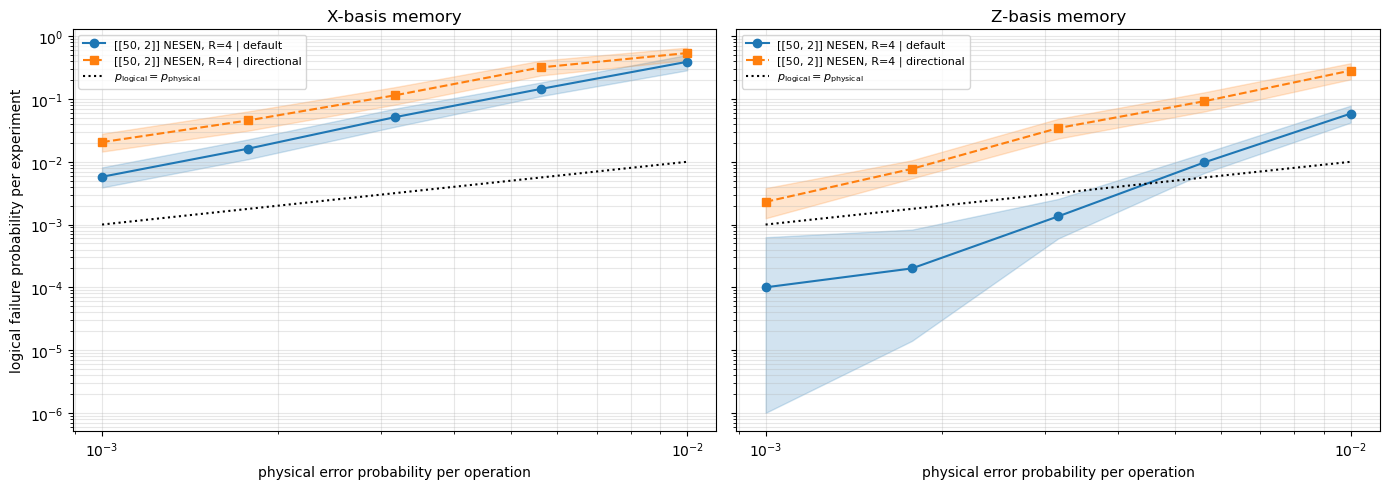

In [9]:
nesen_codes = [
    (dtc.DirectionalTileCode(M=4, N=4, word=dtc.DirectionalWord("NESEN")), 4)
]
bp_lsd_decoder = decoders.SinterDecoder(
    decoder=decoders.bp_lsd(
        max_iter=30,
        bp_method="ms",
        lsd_method="LSD_CS",
        lsd_order=0,
    )
)

plot_fixed_basis_results(nesen_codes, bp_lsd_decoder)
plt.show()

## NNESENN

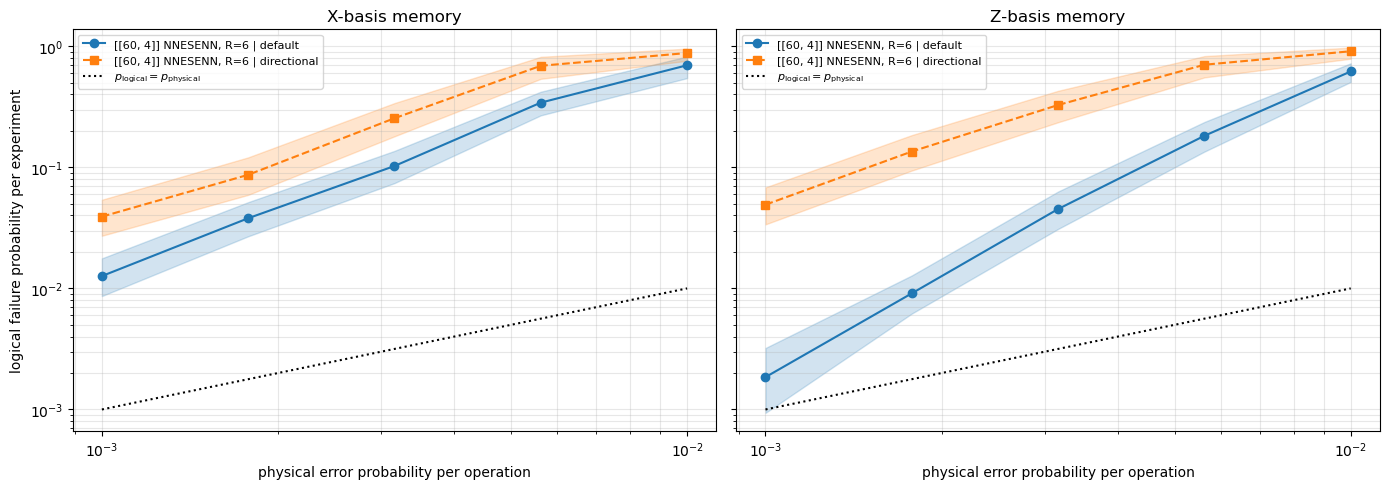

In [5]:
nnesenn_codes = [
    (dtc.DirectionalTileCode(M=4, N=4, word=dtc.DirectionalWord("NNESENN")), 6)
]

plot_fixed_basis_results(nnesenn_codes, bp_lsd_decoder)
plt.show()